<a href="https://colab.research.google.com/github/ansh10tripathi/ML-Learning-Journey/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
pip install numpy matplotlib scikit-learn pillow

Original image shape [[253 254 253 ... 255 255 254]
 [254 254 254 ... 254 254 254]
 [253 254 253 ... 254 254 254]
 ...
 [254 255 254 ... 255 254 255]
 [254 255 255 ... 255 255 255]
 [253 254 254 ... 254 254 253]]
Reconstructed Image Shape:  [[253.12341888 254.03130691 253.35749036 ... 253.73358299 253.80169467
  254.06849302]
 [253.12326748 254.03087192 253.35882391 ... 253.73846017 253.80423689
  254.06883856]
 [253.12091757 254.02997346 253.35318266 ... 253.74031088 253.80572314
  254.06739885]
 ...
 [253.12236275 254.03098877 253.35737454 ... 253.73825179 253.80571639
  254.06869427]
 [253.12164944 254.03072368 253.35733297 ... 253.73800024 253.80359526
  254.06877335]
 [253.12266387 254.03101499 253.35832189 ... 253.74047378 253.80516806
  254.06778121]]


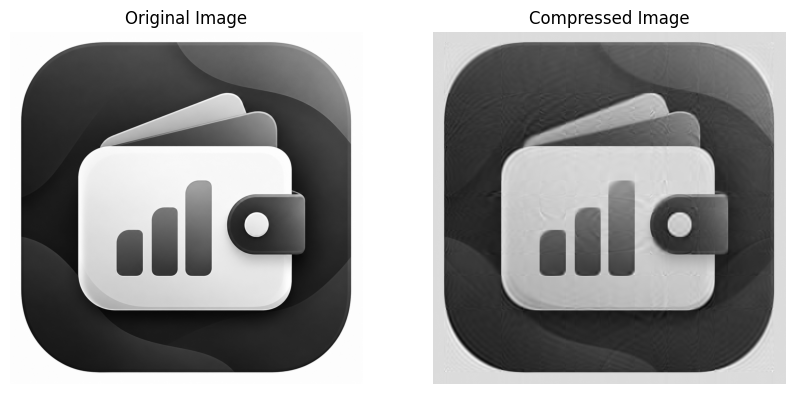

Original Image Size:  1572516
Compressed Image Size:  66462
Number of Principal Components: 53
Explained variance Ratio:  [5.26355655e-01 2.32048393e-01 6.29760229e-02 3.83021043e-02
 2.74151208e-02 1.70847996e-02 1.56523994e-02 1.01101275e-02
 8.11063489e-03 7.17798028e-03 6.14749312e-03 3.81657680e-03
 3.56015361e-03 3.38155979e-03 2.62310281e-03 2.19507319e-03
 2.01441569e-03 1.60314993e-03 1.52527776e-03 1.48764588e-03
 1.32766063e-03 1.25881041e-03 1.04667142e-03 9.46368560e-04
 8.85715237e-04 8.15098519e-04 7.61763892e-04 6.89289353e-04
 5.92064797e-04 5.70376366e-04 5.31342589e-04 5.07672014e-04
 4.99995124e-04 4.81347299e-04 4.30440877e-04 4.10700282e-04
 3.82023267e-04 3.74133349e-04 3.54596121e-04 3.43142913e-04
 3.27261136e-04 3.09371906e-04 2.97263918e-04 2.89351751e-04
 2.67313046e-04 2.63354442e-04 2.53759683e-04 2.51371274e-04
 2.31155705e-04 2.24498662e-04 2.17249770e-04 2.15959055e-04
 2.11669018e-04]


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA


image = Image.open("/content/Glossy Green Wallet Finance Icon.png").convert("L")

img_array = np.array(image)

print("Original image shape",img_array)


pca = PCA(n_components=0.99)

compressed_data = pca.fit_transform(img_array)

compressed_image = pca.inverse_transform(compressed_data)

print("Reconstructed Image Shape: ", compressed_image)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img_array,cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(compressed_image,cmap="gray")
plt.title("Compressed Image")
plt.axis("off")
plt.show()

print("Original Image Size: ",img_array.size)
print("Compressed Image Size: ",compressed_data.size)
print("Number of Principal Components:", pca.n_components_)
print("Explained variance Ratio: ", pca.explained_variance_ratio_)

In [2]:
pip install numpy pandas matplotlib seaborn scikit-learn

Original Dataset Shape: (70000, 784)
Dataset Shape: (5000, 784)
Reduced Shape: (5000, 148)
Reconstructed Shape: (5000, 784)


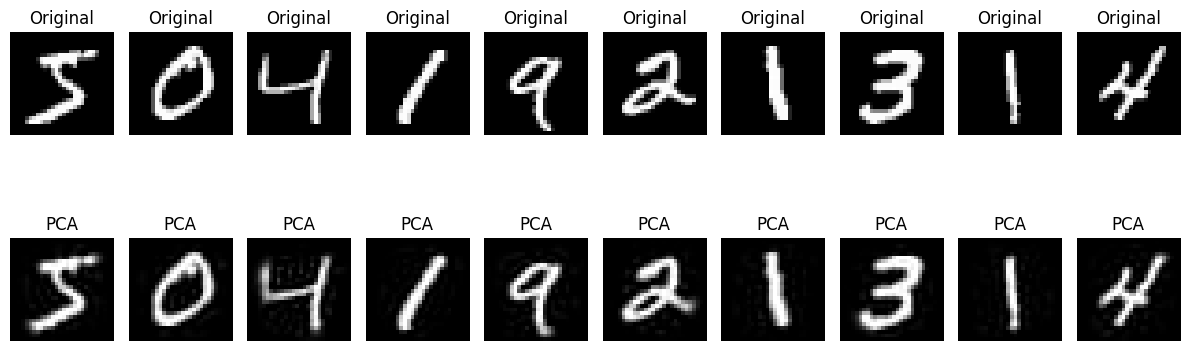

Original Features: 784
Compressed Image Size: 740000
Number of Principal Components: 148
Explained Variance: 0.9501
Dimensionality Reduction: 81.12 %


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

mnist = fetch_openml('mnist_784', version=1, as_frame=False)


X = mnist.data
y = mnist.target.astype(int)

print("Original Dataset Shape:", X.shape)

X = X[:5000]

print("Dataset Shape:", X.shape)

X = X / 255.0

# 3. Apply PCA
pca = PCA(n_components=0.95)
X_compressed = pca.fit_transform(X)

print("Reduced Shape:", X_compressed.shape)


# 4. Reconstruct the images
X_reconstructed = pca.inverse_transform(X_compressed)

print("Reconstructed Shape:", X_reconstructed.shape)



# 5. Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(X_reconstructed[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    plt.title("PCA")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Original Features:", X.shape[1])
print("Compressed Image Size:", X_compressed.size)
print("Number of Principal Components:", pca.n_components_)

print("Explained Variance:",
      round(pca.explained_variance_ratio_.sum(), 4))

reduction = (1 - X_compressed.shape[1] / X.shape[1]) * 100

print("Dimensionality Reduction:", round(reduction, 2), "%")